# **E-commerce Customer Experience Analysis**

Analyzing customer journeys and experiences to identify the factors that influence customer satisfaction, delivery delays, and the likelihood of repeat purchases

In [2]:
import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
engine = create_engine('mysql+pymysql://root:@localhost:3306/ecommerce_db') #connection to the database
query = "SELECT * FROM sales_analytics;" #query to get all the data from the orders table
df = pd.read_sql(query, engine) #read the data into a pandas dataframe

df.head()


,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [4]:
print("Dataset Dimensions (Rows & Columns):", df.shape)
print("\nDescriptive Statistics for Customer Rating and Delivery Days:")
df[['customer_rating', 'delivery_days', 'discount', 'revenue']].describe()

Dataset Dimensions (Rows & Columns): (5000, 12)

Descriptive Statistics for Customer Rating and Delivery Days:


,customer_rating,delivery_days,discount,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,2.973980,6.118800,0.179984,1021.955148
std,1.157722,3.153264,0.101404,825.584219
min,1.000000,1.000000,0.000000,11.210000
25%,2.000000,3.000000,0.090000,354.527500
50%,3.000000,6.000000,0.180000,796.650000
75%,4.000000,9.000000,0.270000,1515.690000
max,5.000000,11.000000,0.350000,4119.330000



Average Customer Rating by Product Category: 
   product_category  customer_rating
0           Beauty         3.008990
1         Clothing         3.005095
2      Electronics         2.951097
3             Home         2.940660


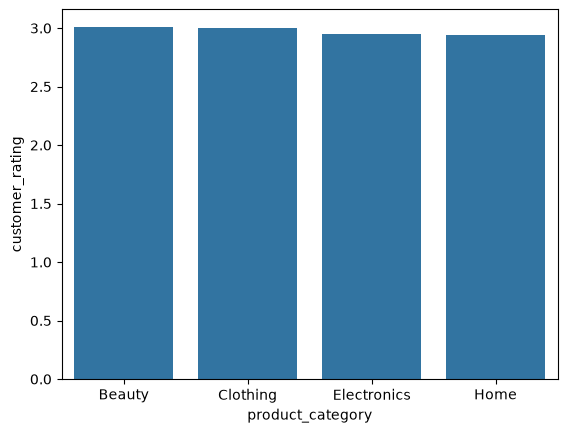

In [5]:
# analaysis of avarage rating by product category
avg_rating_by_category = df.groupby('product_category')['customer_rating'].mean().reset_index()
print("\nAverage Customer Rating by Product Category: \n", avg_rating_by_category)
plot = sns.barplot(x='product_category', y='customer_rating', data=avg_rating_by_category)

Based on an exploratory analysis of 5,000 e-commerce transaction records, the overall average customer rating stands at 2.97 out of 5.0. This indicates a suboptimal level of customer satisfaction (below the neutral threshold of 3.0), revealing systemic customer experience issues that require immediate investigation. This project aims to conduct a deep-dive analysis into the root causes of customer dissatisfaction, focusing particularly on delivery lead times and their correlation with user ratings.

C:\Users\Hamba Allah\AppData\Local\Temp\ipykernel_16116\4122757393.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='delivery_days', y='customer_rating', data=df, palette='Set2')


Text(0, 0.5, 'Customer Rating')

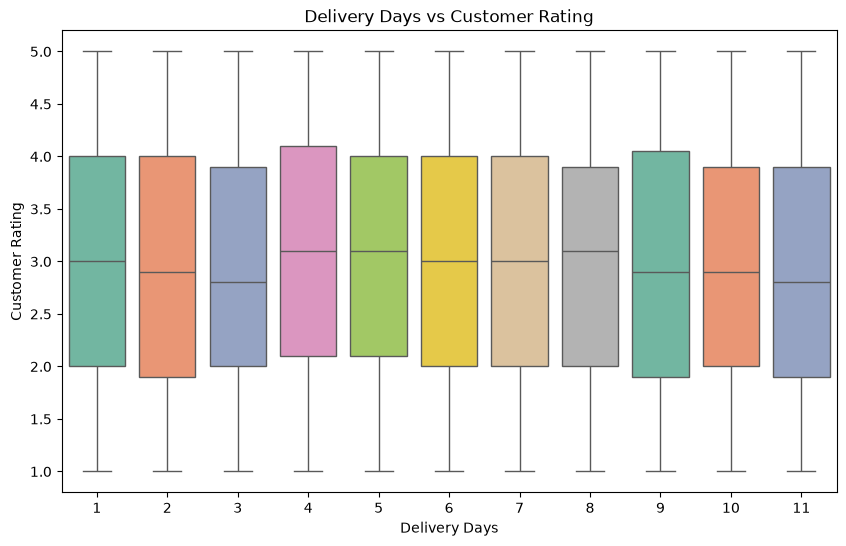

In [9]:
# Delivery Days vs Customer Rating
plt.figure(figsize=(10, 6))
sns.boxplot(x='delivery_days', y='customer_rating', data=df, palette='Set2')
plt.title('Delivery Days vs Customer Rating')
plt.xlabel('Delivery Days')
plt.ylabel('Customer Rating')

**Absence of Correlation Between Delivery Days & Customer Rating**

- Visual analysis via boxplots reveals a uniform distribution of customer ratings across all delivery durations (ranging from 1 to 11 days).

- Analyst Conclusion: Faster delivery lead times (1–3 days) do not inherently yield higher satisfaction scores, nor do longer shipping windows (9–11 days) significantly degrade customer ratings.

- Business Implication: The suboptimal overall rating (~2.97) is not driven by logistical delivery speeds. Management should redirect focus toward qualitative parameters such as product accuracy, packaging quality, and post-purchase customer support.

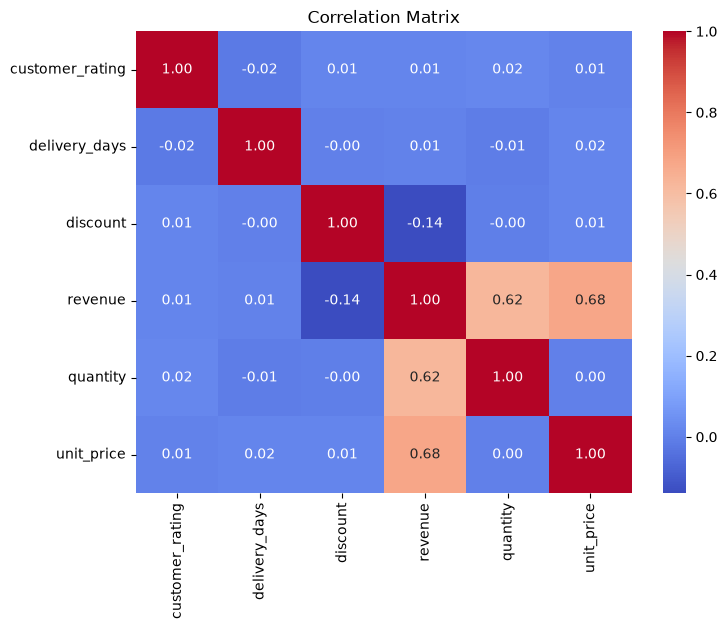

In [12]:
# heatmap of correlation between numerical features
plt.figure(figsize=(8, 6))
correlation_matrix = df[['customer_rating', 'delivery_days', 'discount', 'revenue', 'quantity', 'unit_price']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f") 
plt.title('Correlation Matrix')
plt.show()

**Conclusion:** The characteristics of this data indicate that the variation in customer satisfaction levels within the dataset is not influenced by quantitative logistical factors, but is instead driven by external qualitative factors (such as product quality, personal expectations, or post-purchase customer service) that are not captured within the core transactional variables.